## Existing Public BERT-Based AI Text Detector

In this notebook, we evaluate an existing public BERT-based AI text detection model on the HC3 dataset. The purpose of this experiment is to test how well a pre-trained detector can distinguish between human-written text and AI-generated text without additional fine-tuning.

### Dataset Preparation

The dataset is loaded from the `all.jsonl` file. Each record contains two types of answers:

- `human_answers`, which are labelled as `0`
- `chatgpt_answers`, which are labelled as `1`

All non-empty answers are extracted and converted into a unified dataframe with two columns:

- `text`: the response content
- `label`: the ground-truth class

This produces a full dataset containing both human-written and AI-generated samples for evaluation.

### Model Selection

The model used in this notebook is:

`pritamdeb68/BERTAIDetector`

This is an existing public sequence classification model from Hugging Face. It is loaded directly with `AutoTokenizer` and `AutoModelForSequenceClassification`. Since the model is already pre-trained for AI text detection, no training or fine-tuning is performed in this notebook. Instead, the model is used directly for inference on the dataset.

### Inference Process

The full dataset is used for prediction. Text samples are processed in batches to improve efficiency. During tokenization:

- padding is applied
- truncation is enabled
- maximum sequence length is set to 256

If a CUDA-enabled GPU is available, the model runs on GPU for faster inference. Mixed precision (`float16`) is also used on CUDA devices to improve performance.

The model outputs logits, which are converted into probabilities using softmax. The predicted label is then obtained by selecting the class with the highest probability.

### Evaluation Metrics

After prediction, the model is evaluated using several standard classification metrics:

- Accuracy
- Precision
- Recall
- F1-score

A full classification report is also generated to show class-wise performance. These metrics help assess the model’s ability to classify human and AI-generated text correctly.

### Output and Visualisation

The notebook saves the prediction results into a CSV file named:

`existing_bert_model_full_predictions.csv`

This file includes:

- original text
- true label
- predicted label
- probability for class 0
- probability for class 1

In addition, two visualisations are produced:

1. **Confusion Matrix**  
   This shows how many samples were correctly or incorrectly classified as human or AI-generated.

2. **Evaluation Metrics Bar Chart**  
   This displays the overall Accuracy, Precision, Recall, and F1-score in a simple visual format.

### Summary

Overall, this notebook demonstrates how an existing public BERT-based AI detector can be applied directly to the HC3 dataset for binary classification. The workflow includes dataset construction, batched inference, quantitative evaluation, result saving, and visual analysis. This experiment serves as a baseline for comparing public pre-trained detectors with other models in the project.

Current working directory: c:\Users\ASUS\Desktop\26T1\6713\ass2\comp6713-ass2\model03_finetuned_bert
Input file exists: True

Full dataset shape: (85431, 2)
Columns: ['text', 'label']

Label distribution:
label
0    58546
1    26885
Name: count, dtype: int64

Full inference shape: (85431, 2)

Full inference label distribution:
label
0    58546
1    26885
Name: count, dtype: int64

Using device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CUDA version: 12.1


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 10601.27it/s]



Loaded model: pritamdeb68/BERTAIDetector
id2label: {0: 'LABEL_0', 1: 'LABEL_1'}
label2id: {'LABEL_0': 0, 'LABEL_1': 1}
Model device: cuda:0
Input device: cuda:0

Unique predicted labels before adjustment: [0 1]

Existing Public BERT AI Detector Results (Full Dataset)
Accuracy : 0.8143
Precision: 0.6342
Recall   : 0.9683
F1-score : 0.7664

Classification Report:
              precision    recall  f1-score   support

           0     0.9808    0.7435    0.8458     58546
           1     0.6342    0.9683    0.7664     26885

    accuracy                         0.8143     85431
   macro avg     0.8075    0.8559    0.8061     85431
weighted avg     0.8717    0.8143    0.8209     85431


Saved predictions to: existing_bert_model_full_predictions.csv

Sample predictions:
                                                text  true_label  pred_label
0  Basically there are many categories of " Best ...           0           0
1  If you 're hearing about it , it 's because it...           0     

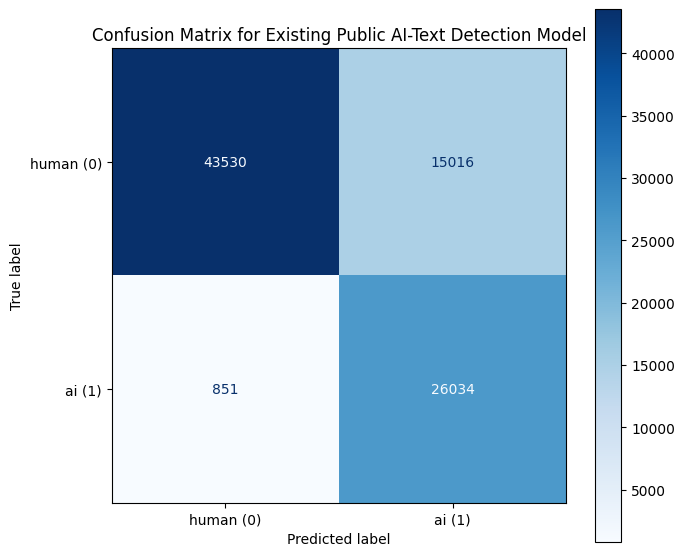

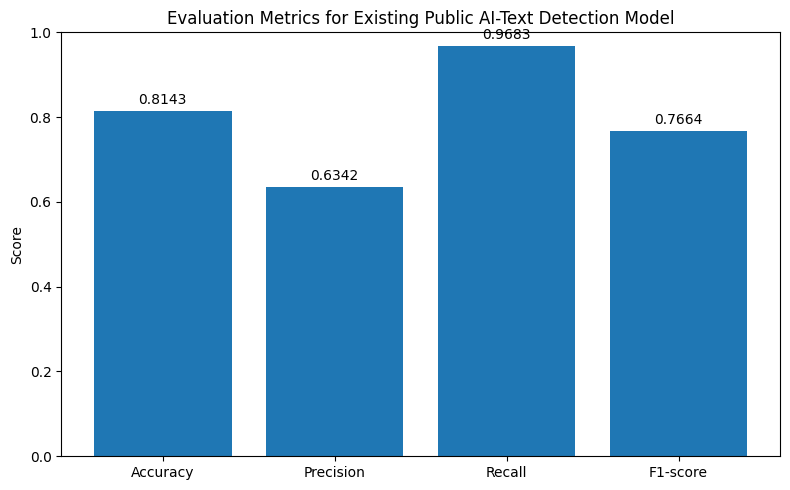

In [5]:
import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# =========================
# 1. Check current working directory
# =========================
print("Current working directory:", os.getcwd())

# =========================
# 2. Load HC3 jsonl file
# 0 = human-written
# 1 = AI-generated
# =========================
input_path = "../data/all.jsonl"
print("Input file exists:", os.path.exists(input_path))

rows = []
with open(input_path, "r", encoding="utf-8") as f:
    for line in f:
        item = json.loads(line)

        for ans in item.get("human_answers", []):
            if isinstance(ans, str) and ans.strip():
                rows.append({
                    "text": ans.strip(),
                    "label": 0
                })

        for ans in item.get("chatgpt_answers", []):
            if isinstance(ans, str) and ans.strip():
                rows.append({
                    "text": ans.strip(),
                    "label": 1
                })

df = pd.DataFrame(rows)

print("\nFull dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nLabel distribution:")
print(df["label"].value_counts().sort_index())

# =========================
# 3. Use full dataset for inference
# =========================
full_df = df.copy()

print("\nFull inference shape:", full_df.shape)
print("\nFull inference label distribution:")
print(full_df["label"].value_counts().sort_index())

# Optional: use a smaller subset for debugging
# full_df = full_df.sample(n=5000, random_state=42)

# =========================
# 4. Device setting
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nUsing device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("CUDA is not available. Running on CPU.")

# =========================
# 5. Load existing public BERT AI detector
# =========================
MODEL_NAME = "pritamdeb68/BERTAIDetector"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print("\nLoaded model:", MODEL_NAME)
print("id2label:", model.config.id2label)
print("label2id:", model.config.label2id)
print("Model device:", next(model.parameters()).device)

# =========================
# 6. Prepare full data
# =========================
full_texts = full_df["text"].astype(str).tolist()
y_true = full_df["label"].astype(int).tolist()

# =========================
# 7. Prediction function
# =========================
def predict_in_batches(texts, tokenizer, model, device, batch_size=32, max_length=256):
    all_preds = []
    all_probs = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        if i == 0:
            print("Input device:", inputs["input_ids"].device)

        with torch.inference_mode():
            if device.type == "cuda":
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    outputs = model(**inputs)
            else:
                outputs = model(**inputs)

            logits = outputs.logits
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    return np.array(all_preds), np.array(all_probs)

# =========================
# 8. Run prediction on full data
# =========================
y_pred, y_prob = predict_in_batches(
    full_texts,
    tokenizer,
    model,
    device,
    batch_size=32,
    max_length=256
)

print("\nUnique predicted labels before adjustment:", np.unique(y_pred))

# =========================
# 9. IMPORTANT:
# Dataset labels:
# 0 = human
# 1 = ai
#
# Check model.config.id2label above.
# If reversed, uncomment below.
# =========================
# y_pred = 1 - y_pred
# y_prob = y_prob[:, ::-1]

# =========================
# 10. Evaluation
# =========================
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="binary", zero_division=0)
recall = recall_score(y_true, y_pred, average="binary", zero_division=0)
f1 = f1_score(y_true, y_pred, average="binary", zero_division=0)

print("\nExisting Public BERT AI Detector Results (Full Dataset)")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, digits=4))

# =========================
# 11. Save predictions
# =========================
results_df = full_df.copy()
results_df["pred_existing_model"] = y_pred
results_df["prob_class_0"] = y_prob[:, 0]
results_df["prob_class_1"] = y_prob[:, 1]

output_path = "existing_bert_model_full_predictions.csv"
results_df.to_csv(output_path, index=False)

print("\nSaved predictions to:", output_path)

# =========================
# 12. Quick manual inspection
# =========================
sample_check = pd.DataFrame({
    "text": full_df["text"].head(10),
    "true_label": y_true[:10],
    "pred_label": y_pred[:10]
})

print("\nSample predictions:")
print(sample_check.head(10))

# =========================
# 13. Confusion matrix
# =========================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:")
print(cm)

# =========================
# 14. Plot confusion matrix
# =========================
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["human (0)", "ai (1)"]
)
disp.plot(cmap="Blues", values_format="d", ax=ax)
ax.set_title("Confusion Matrix for Existing Public AI-Text Detection Model")
plt.tight_layout()
plt.show()

# =========================
# 15. Plot evaluation metrics
# =========================
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
values = [accuracy, precision, recall, f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Evaluation Metrics for Existing Public AI-Text Detection Model")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()